In [2]:
import sys
import os
sys.path.append(os.path.abspath('../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.cox import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import jinja2

import time
set_config(display="text")  # displays text representation of estimators

In [3]:
dataset = pd.read_csv("data/cleaning/data_treated_clean.csv")

# Load feature lists
features_retained = []
with open("data/cleaning/features_retained.txt", "r") as file:
    for line in file:
        features_retained.append(line.strip())

feature_columns = features_retained

survival_dataset = dataset

In [5]:
# Separate binary and continuous features from feature_columns in survival_dataset
# Results will populate `binary_features` and `continuous_features` for use in later cells.

df_feat = survival_dataset[feature_columns]

binary_features = []
continuous_features = []
other_features = []

for col in df_feat.columns:
    ser = df_feat[col].dropna()
    # Try to coerce object dtypes to numeric if needed
    if ser.dtype == object:
        try:
            ser = pd.to_numeric(ser, errors="coerce").dropna()
        except Exception:
            other_features.append(col)
            continue

    if ser.empty:
        other_features.append(col)
        continue

    uniq = np.unique(ser)
    # treat boolean-like or exactly {0,1} as binary
    if np.all(np.isin(uniq, [0, 1])):
        binary_features.append(col)
    # If only two unique values but not 0/1 (e.g. {2,3}) treat as binary as well
    elif len(uniq) == 2:
        binary_features.append(col)
    else:
        # otherwise consider continuous (numeric with >2 unique values)
        continuous_features.append(col)

# Small summary
print(f"Binary features ({len(binary_features)}): {binary_features[:10]}{'...' if len(binary_features)>10 else ''}")
print(f"Continuous features ({len(continuous_features)}): {continuous_features[:10]}{'...' if len(continuous_features)>10 else ''}")
if other_features:
    print(f"Other features ({len(other_features)}): {other_features}")

# expose as variables for downstream cells
binary_features = binary_features
continuous_features = continuous_features

Binary features (16): ['Adjuvant chemotherapy_1', 'Adjuvant therapy with bio drugs', 'Axillary operation', 'Chemotherapy performed_1', 'Endocrine therapy performed_1', 'Progesterone receptor status at CB_0.0', 'Radiotherapy (RT) performed', 'Radiotherapy on chest wall', 'Radiotherapy on internal mammary chain', 'Radiotherapy on supraclavicular area']...
Continuous features (6): ['Age', 'Boost dose administered', 'Conventional RT fraction', 'Ki67 positive cells (%) at CB', 'N (Regional nodes affected)', 'Total administered dose']


In [102]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [103]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']
event_indicator = survival_dataset['Regional LN recurrence']

In [104]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [105]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [106]:
print("Train events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Val events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0


In [107]:
x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]
sgkf_1 = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

In [108]:
# Scale features for FINAL MODEL training and test evaluation
# NOTE: This scaling is ONLY for final model training after CV hyperparameter selection
# During CV, scaling happens INSIDE each fold (see cox_cross_validation function)
# Without scaling, L1 penalty affects features with different ranges unequally

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# convert scaled arrays back to DataFrame (preserve original columns and indices)
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns, index=x_test.index)

In [109]:
l1_ratio = 1.0
model = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio)
alphas = np.logspace(-4, -2, 20)
list_alphas = alphas.tolist()
alphas = pd.DataFrame(list_alphas, columns=['Alphas'])

In [110]:
# Test multiple alpha values to find the best one
results_all_alphas = {}
metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

for alpha in list_alphas:
    print(f"Testing alpha: {alpha:.4f}")
    results_df = cox_cross_validation(x_train, y_train, sgkf_1, alpha=alpha, l1_ratio=l1_ratio, metrics=metrics, scaler_class='standard', 
                                      binary_features=binary_features, continuous_features=continuous_features)
    results_all_alphas[alpha] = results_df

Testing alpha: 0.0001


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: ConvergenceWarning: Optimization terminated early, you might want to increase the number of iterations (max_iter=100000).
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:69: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:80: RuntimeWarning: invalid value encountered in scalar subtract
  value -= risk_score[k : (k + d)].sum()
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


ValueError: Input estimate contains NaN.

In [ ]:
# Get summaries for each metric
cindex_summary = create_alpha_summary(results_all_alphas, 'c-index')
ipcw_summary = create_alpha_summary(results_all_alphas, 'c-index-ipcw')
brier_summary = create_alpha_summary(results_all_alphas, 'int-brier-score')

print("C-Index Results:")
print(cindex_summary.sort_values('Mean', ascending=False).head())
print("\nIPCW C-Index Results:")
print(ipcw_summary.sort_values('Mean', ascending=False).head())
print("\nBrier Score Results (lower is better):")
print(brier_summary.sort_values('Mean', ascending=True).head())

C-Index Results:
      Alpha      Mean       Std
8  0.000695  0.789099  0.145270
7  0.000546  0.786961  0.154174
6  0.000428  0.783914  0.160146
5  0.000336  0.778682  0.164950
9  0.000886  0.775698  0.151087

IPCW C-Index Results:
       Alpha      Mean       Std
8   0.000695  0.691864  0.171080
7   0.000546  0.686941  0.185444
9   0.000886  0.684941  0.153702
6   0.000428  0.681032  0.187523
10  0.001129  0.680018  0.148650

Brier Score Results (lower is better):
       Alpha      Mean       Std
18  0.007848  0.018816  0.006573
17  0.006158  0.018824  0.006511
19  0.010000  0.018825  0.006567
16  0.004833  0.018859  0.006434
15  0.003793  0.018905  0.006351


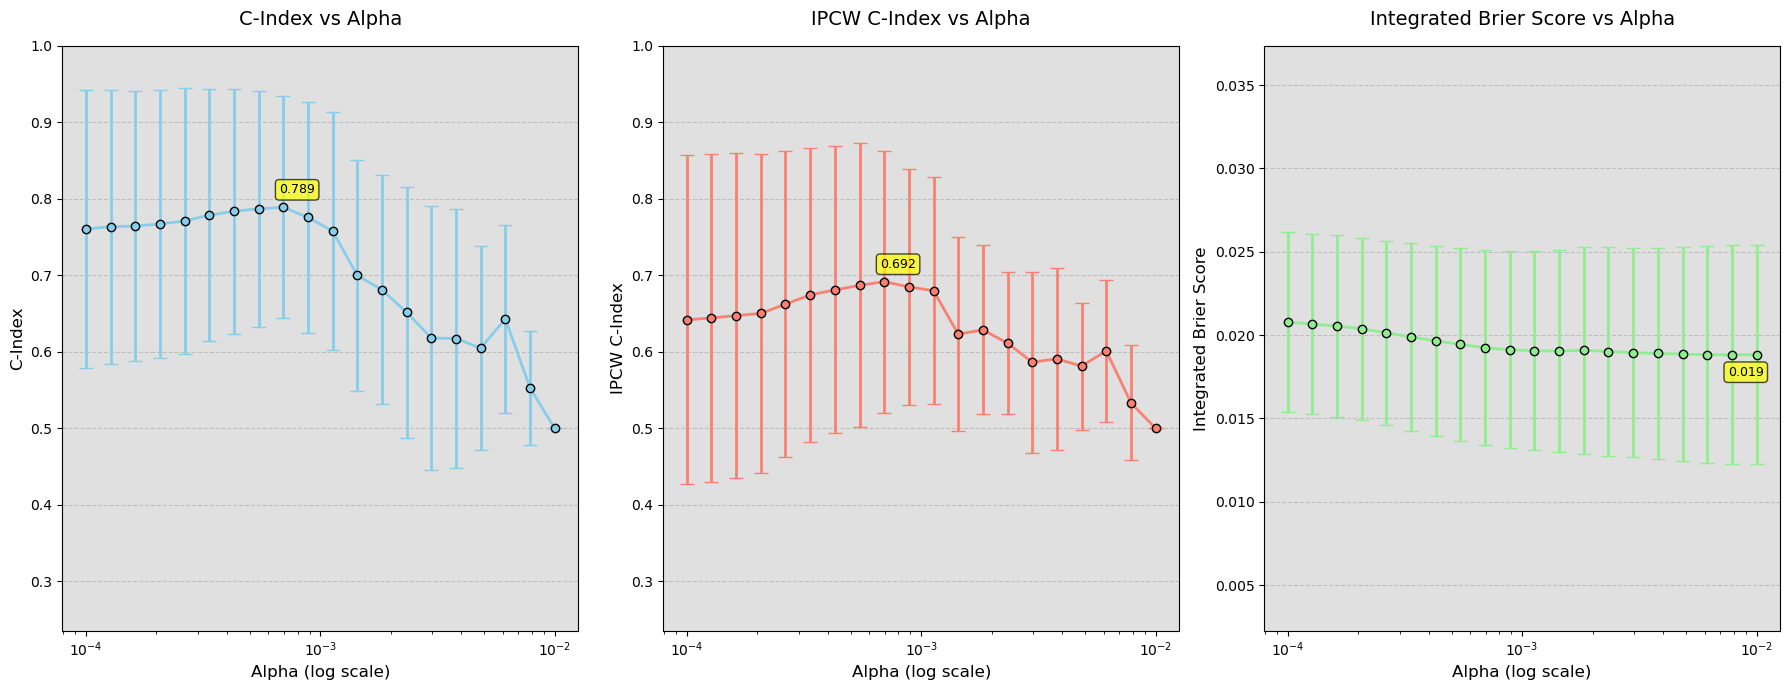

In [ ]:
# Plot the results to visualize alpha performance with improved aesthetics
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Set the background color of the figure
fig.patch.set_facecolor('None')

# Calculate global y-axis limits for consistent scaling
# For C-Index and IPCW C-Index (higher is better)
all_cindex_values = list(cindex_summary['Mean']) + list(ipcw_summary['Mean'])
all_cindex_stds = list(cindex_summary['Std']) + list(ipcw_summary['Std'])
cindex_min = min(all_cindex_values) - max(all_cindex_stds) - 0.05
cindex_max = max(all_cindex_values) + max(all_cindex_stds) + 0.05
cindex_min = max(0, cindex_min)  # Don't go below 0
cindex_max = min(1, cindex_max)  # Don't go above 1

# For Brier Score (lower is better) - keep its own scale but don't auto-fit
brier_min = brier_summary['Mean'].min() - brier_summary['Std'].max() - 0.01
brier_max = brier_summary['Mean'].max() + brier_summary['Std'].max() + 0.01

# C-Index plot
axes[0].set_facecolor('#e0e0e0')
axes[0].errorbar(cindex_summary['Alpha'], cindex_summary['Mean'], 
                yerr=cindex_summary['Std'], fmt='o-', capsize=5, color='skyblue', 
                markeredgecolor='black', linewidth=2, markersize=6)
axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (log scale)', fontsize=12)
axes[0].set_ylabel('C-Index', fontsize=12)
axes[0].set_title('C-Index vs Alpha', fontsize=14, pad=15)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
axes[0].set_ylim(cindex_min, cindex_max)

# IPCW C-Index plot
axes[1].set_facecolor('#e0e0e0')
axes[1].errorbar(ipcw_summary['Alpha'], ipcw_summary['Mean'], 
                yerr=ipcw_summary['Std'], fmt='o-', capsize=5, color='salmon',
                markeredgecolor='black', linewidth=2, markersize=6)
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (log scale)', fontsize=12)
axes[1].set_ylabel('IPCW C-Index', fontsize=12)
axes[1].set_title('IPCW C-Index vs Alpha', fontsize=14, pad=15)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
axes[1].set_ylim(cindex_min, cindex_max)  # Same scale as C-Index

# Brier Score plot
axes[2].set_facecolor('#e0e0e0')
axes[2].errorbar(brier_summary['Alpha'], brier_summary['Mean'], 
                yerr=brier_summary['Std'], fmt='o-', capsize=5, color='lightgreen',
                markeredgecolor='black', linewidth=2, markersize=6)
axes[2].set_xscale('log')
axes[2].set_xlabel('Alpha (log scale)', fontsize=12)
axes[2].set_ylabel('Integrated Brier Score', fontsize=12)
axes[2].set_title('Integrated Brier Score vs Alpha', fontsize=14, pad=15)
axes[2].grid(axis='y', linestyle='--', alpha=0.7)
axes[2].set_ylim(brier_min, brier_max)  # Fixed range, not auto-fitted

# Add value annotations for best performing alphas
# C-Index best value
best_cindex_idx = cindex_summary['Mean'].idxmax()
best_cindex_alpha = cindex_summary.loc[best_cindex_idx, 'Alpha']
best_cindex_value = cindex_summary.loc[best_cindex_idx, 'Mean']
axes[0].annotate(f'{best_cindex_value:.3f}', 
                xy=(best_cindex_alpha, best_cindex_value),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

# IPCW best value
best_ipcw_idx = ipcw_summary['Mean'].idxmax()
best_ipcw_alpha = ipcw_summary.loc[best_ipcw_idx, 'Alpha']
best_ipcw_value = ipcw_summary.loc[best_ipcw_idx, 'Mean']
axes[1].annotate(f'{best_ipcw_value:.3f}', 
                xy=(best_ipcw_alpha, best_ipcw_value),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

# Brier best value (minimum)
best_brier_idx = brier_summary['Mean'].idxmin()
best_brier_alpha = brier_summary.loc[best_brier_idx, 'Alpha']
best_brier_value = brier_summary.loc[best_brier_idx, 'Mean']
axes[2].annotate(f'{best_brier_value:.3f}', 
                xy=(best_brier_alpha, best_brier_value),
                xytext=(10, -15), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate best alphas on test set
print("=== TEST SET EVALUATION WITH BEST ALPHAS ===\n")

# Test set results for each metric's best alpha
test_results = {}

# 1. C-Index best alpha
print("1. Testing C-Index best alpha...")
cindex_best_alpha = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)
model_cindex = CoxnetSurvivalAnalysis(alphas=[cindex_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_cindex.fit(x_train, y_train)

# Get test predictions
predicted_risk_cindex = model_cindex.predict(x_test)

# Calculate all metrics for this model
test_cindex = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_cindex)[0]
max_time = min(y_train['time'].max(), y_test['time'].max()) * 0.9
test_ipcw_cindex = concordance_index_ipcw(y_train, y_test, predicted_risk_cindex, tau=max_time)[0]

# Brier score
surv_funcs_cindex = model_cindex.predict_survival_function(x_test)
times = np.array([2*365, 5*365, 10*365])
times = times[times <= max_time]
if len(times) > 0:
    predicted_survival_probs_cindex = np.asarray([[fn(t) for t in times] for fn in surv_funcs_cindex])
    test_brier_cindex = integrated_brier_score(y_train, y_test, predicted_survival_probs_cindex, times)
else:
    test_brier_cindex = np.nan

test_results['c-index_best'] = {
    'alpha': cindex_best_alpha,
    'c-index': test_cindex,
    'c-index-ipcw': test_ipcw_cindex,
    'int-brier-score': test_brier_cindex,
    'n_features': np.sum(model_cindex.coef_.flatten() != 0)
}

print(f"Alpha: {cindex_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_cindex:.4f}")
print(f"Test Brier Score: {test_brier_cindex:.4f}")
print(f"Selected Features: {test_results['c-index_best']['n_features']}")
print("-" * 50)

=== TEST SET EVALUATION WITH BEST ALPHAS ===

1. Testing C-Index best alpha...
Best alpha for C-Index: 0.0007
Score: 0.7891 ± 0.1453
Alpha: 0.0007
Test C-Index: 0.7170
Test IPCW C-Index: 0.5403
Test Brier Score: 0.0102
Selected Features: 13
--------------------------------------------------


In [ ]:
# 2. IPCW C-Index best alpha
print("2. Testing IPCW C-Index best alpha...")
ipcw_best_alpha = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)
model_ipcw = CoxnetSurvivalAnalysis(alphas=[ipcw_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_ipcw.fit(x_train, y_train)

predicted_risk_ipcw = model_ipcw.predict(x_test)
test_cindex_ipcw = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_ipcw)[0]
test_ipcw_ipcw = concordance_index_ipcw(y_train, y_test, predicted_risk_ipcw, tau=max_time)[0]

surv_funcs_ipcw = model_ipcw.predict_survival_function(x_test)
if len(times) > 0:
    predicted_survival_probs_ipcw = np.asarray([[fn(t) for t in times] for fn in surv_funcs_ipcw])
    test_brier_ipcw = integrated_brier_score(y_train, y_test, predicted_survival_probs_ipcw, times)
else:
    test_brier_ipcw = np.nan

test_results['ipcw_best'] = {
    'alpha': ipcw_best_alpha,
    'c-index': test_cindex_ipcw,
    'c-index-ipcw': test_ipcw_ipcw,
    'int-brier-score': test_brier_ipcw,
    'n_features': np.sum(model_ipcw.coef_.flatten() != 0)
}

print(f"Alpha: {ipcw_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex_ipcw:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_ipcw:.4f}")
print(f"Test Brier Score: {test_brier_ipcw:.4f}")
print(f"Selected Features: {test_results['ipcw_best']['n_features']}")
print("-" * 50)

2. Testing IPCW C-Index best alpha...
Best alpha for IPCW C-Index: 0.0007
Score: 0.6919 ± 0.1711
Alpha: 0.0007
Test C-Index: 0.7170
Test IPCW C-Index: 0.5403
Test Brier Score: 0.0102
Selected Features: 13
--------------------------------------------------


In [ ]:
# 3. Brier Score best alpha
print("3. Testing Brier Score best alpha...")
brier_best_alpha = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)
model_brier = CoxnetSurvivalAnalysis(alphas=[brier_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_brier.fit(x_train, y_train)

predicted_risk_brier = model_brier.predict(x_test)
test_cindex_brier = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_brier)[0]
test_ipcw_brier = concordance_index_ipcw(y_train, y_test, predicted_risk_brier, tau=max_time)[0]

surv_funcs_brier = model_brier.predict_survival_function(x_test)
if len(times) > 0:
    predicted_survival_probs_brier = np.asarray([[fn(t) for t in times] for fn in surv_funcs_brier])
    test_brier_brier = integrated_brier_score(y_train, y_test, predicted_survival_probs_brier, times)
else:
    test_brier_brier = np.nan

test_results['brier_best'] = {
    'alpha': brier_best_alpha,
    'c-index': test_cindex_brier,
    'c-index-ipcw': test_ipcw_brier,
    'int-brier-score': test_brier_brier,
    'n_features': np.sum(model_brier.coef_.flatten() != 0)
}

print(f"Alpha: {brier_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex_brier:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_brier:.4f}")
print(f"Test Brier Score: {test_brier_brier:.4f}")
print(f"Selected Features: {test_results['brier_best']['n_features']}")
print("-" * 50)

3. Testing Brier Score best alpha...
Best alpha for Brier Score: 0.0078
Score: 0.0188 ± 0.0066
Alpha: 0.0078
Test C-Index: 0.7126
Test IPCW C-Index: 0.7090
Test Brier Score: 0.0102
Selected Features: 2
--------------------------------------------------


In [ ]:
# Create summary table of test results
print("=== SUMMARY OF TEST SET RESULTS ===")
test_summary = pd.DataFrame(test_results).T
test_summary.index = ['Best for C-Index', 'Best for IPCW C-Index', 'Best for Brier Score']

# Round for better display
test_summary_display = test_summary.copy()
for col in ['c-index', 'c-index-ipcw', 'int-brier-score']:
    test_summary_display[col] = test_summary_display[col].round(4)
test_summary_display['alpha'] = test_summary_display['alpha'].round(4)

print(test_summary_display)

# Highlight the best performance for each metric
print("\n=== BEST TEST PERFORMANCE BY METRIC ===")
print(f"Best C-Index: {test_summary['c-index'].max():.4f} (Alpha: {test_summary.loc[test_summary['c-index'].idxmax(), 'alpha']:.4f})")
print(f"Best IPCW C-Index: {test_summary['c-index-ipcw'].max():.4f} (Alpha: {test_summary.loc[test_summary['c-index-ipcw'].idxmax(), 'alpha']:.4f})")
print(f"Best Brier Score: {test_summary['int-brier-score'].min():.4f} (Alpha: {test_summary.loc[test_summary['int-brier-score'].idxmin(), 'alpha']:.4f})")

=== SUMMARY OF TEST SET RESULTS ===
                        alpha  c-index  c-index-ipcw  int-brier-score  \
Best for C-Index       0.0007   0.7170        0.5403           0.0102   
Best for IPCW C-Index  0.0007   0.7170        0.5403           0.0102   
Best for Brier Score   0.0078   0.7126        0.7090           0.0102   

                       n_features  
Best for C-Index             13.0  
Best for IPCW C-Index        13.0  
Best for Brier Score          2.0  

=== BEST TEST PERFORMANCE BY METRIC ===
Best C-Index: 0.7170 (Alpha: 0.0007)
Best IPCW C-Index: 0.7090 (Alpha: 0.0078)
Best Brier Score: 0.0102 (Alpha: 0.0007)


In [ ]:
# Show selected features for each best alpha model
print("=== SELECTED FEATURES BY BEST ALPHA MODELS ===\n")

# Get the best alphas
best_alpha_cindex = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)
best_alpha_ipcw = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)
best_alpha_brier = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)

# Train models with best alphas and get selected features
models_features = {}

# 1. C-Index best alpha model
print(f"1. C-INDEX BEST ALPHA MODEL (α = {best_alpha_cindex:.4f}):")
model_cindex = CoxnetSurvivalAnalysis(alphas=[best_alpha_cindex], l1_ratio=l1_ratio, fit_baseline_model=True)
model_cindex.fit(x_train, y_train)

cindex_features = []
for feature, coef in zip(model_cindex.feature_names_in_, model_cindex.coef_.flatten()):
    if coef != 0:
        cindex_features.append({'feature': feature, 'coefficient': coef})

cindex_features_df = pd.DataFrame(cindex_features).sort_values('coefficient', key=abs, ascending=False)
models_features['c-index'] = cindex_features_df

print(f"   Number of selected features: {len(cindex_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in cindex_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(cindex_features_df) > 10:
    print(f"     ... and {len(cindex_features_df) - 10} more features")
print()

# 2. IPCW C-Index best alpha model
print(f"2. IPCW C-INDEX BEST ALPHA MODEL (α = {best_alpha_ipcw:.4f}):")
model_ipcw = CoxnetSurvivalAnalysis(alphas=[best_alpha_ipcw], l1_ratio=l1_ratio, fit_baseline_model=True)
model_ipcw.fit(x_train, y_train)

ipcw_features = []
for feature, coef in zip(model_ipcw.feature_names_in_, model_ipcw.coef_.flatten()):
    if coef != 0:
        ipcw_features.append({'feature': feature, 'coefficient': coef})

ipcw_features_df = pd.DataFrame(ipcw_features).sort_values('coefficient', key=abs, ascending=False)
models_features['c-index-ipcw'] = ipcw_features_df

print(f"   Number of selected features: {len(ipcw_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in ipcw_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(ipcw_features_df) > 10:
    print(f"     ... and {len(ipcw_features_df) - 10} more features")
print()

# 3. Brier Score best alpha model
print(f"3. BRIER SCORE BEST ALPHA MODEL (α = {best_alpha_brier:.4f}):")
model_brier = CoxnetSurvivalAnalysis(alphas=[best_alpha_brier], l1_ratio=l1_ratio, fit_baseline_model=True)
model_brier.fit(x_train, y_train)

brier_features = []
for feature, coef in zip(model_brier.feature_names_in_, model_brier.coef_.flatten()):
    if coef != 0:
        brier_features.append({'feature': feature, 'coefficient': coef})

brier_features_df = pd.DataFrame(brier_features).sort_values('coefficient', key=abs, ascending=False)
models_features['int-brier-score'] = brier_features_df

print(f"   Number of selected features: {len(brier_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in brier_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(brier_features_df) > 10:
    print(f"     ... and {len(brier_features_df) - 10} more features")
print()

# Feature overlap analysis
print("=== FEATURE SELECTION OVERLAP ANALYSIS ===")
cindex_set = set(cindex_features_df['feature'])
ipcw_set = set(ipcw_features_df['feature'])
brier_set = set(brier_features_df['feature'])

# Common features across all models
common_all = cindex_set & ipcw_set & brier_set
print(f"Features selected by ALL models: {len(common_all)}")
if common_all:
    print(f"   {list(common_all)}")

# Pairwise overlaps
common_cindex_ipcw = cindex_set & ipcw_set
common_cindex_brier = cindex_set & brier_set
common_ipcw_brier = ipcw_set & brier_set

print(f"\nFeatures selected by C-Index AND IPCW models: {len(common_cindex_ipcw)}")
print(f"Features selected by C-Index AND Brier models: {len(common_cindex_brier)}")
print(f"Features selected by IPCW AND Brier models: {len(common_ipcw_brier)}")

# Unique features
unique_cindex = cindex_set - ipcw_set - brier_set
unique_ipcw = ipcw_set - cindex_set - brier_set
unique_brier = brier_set - cindex_set - ipcw_set

print(f"\nFeatures UNIQUE to C-Index model: {len(unique_cindex)}")
print(f"Features UNIQUE to IPCW model: {len(unique_ipcw)}")
print(f"Features UNIQUE to Brier model: {len(unique_brier)}")

=== SELECTED FEATURES BY BEST ALPHA MODELS ===

Best alpha for C-Index: 0.0007
Score: 0.7891 ± 0.1453
Best alpha for IPCW C-Index: 0.0007
Score: 0.6919 ± 0.1711
Best alpha for Brier Score: 0.0078
Score: 0.0188 ± 0.0066
1. C-INDEX BEST ALPHA MODEL (α = 0.0007):
   Number of selected features: 13
   Selected features (sorted by absolute coefficient value):
     Adjuvant therapy with bio drugs: -1.7276
     Endocrine therapy performed_1: 1.3157
     State (if hormone therapy prescribed): -1.1441
     Radiotherapy on supraclavicular area: 0.3641
     Side location of the lesion: -0.3242
     N (Regional nodes affected): 0.2849
     Progesterone receptor status at CB_0.0: 0.0755
     Radiotherapy (RT) performed: -0.0722
     Boost dose administered: -0.0588
     Conventional RT fraction: -0.0286
     ... and 3 more features

2. IPCW C-INDEX BEST ALPHA MODEL (α = 0.0007):
   Number of selected features: 13
   Selected features (sorted by absolute coefficient value):
     Adjuvant therapy wit